In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("dataset_09.csv", header=None)

In [3]:
df.sample()

,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
10681,0,tcp,ftp_data,SF,3888.0,0.0,0.0,0.0,0.0,0.0,...,105.0,0.7,0.09,0.7,0.02,0.0,0.01,0.0,0.0,normal


In [21]:
numeric_df = df.apply(pd.to_numeric, errors="coerce")

numeric_df = numeric_df.dropna(axis=1, how="all")

numeric_df = numeric_df.replace(
    [np.inf, -np.inf], np.nan
)

numeric_df = numeric_df.fillna(numeric_df.median())


df = numeric_df.copy()

In [22]:
print("Selected numerical columns:")
print(df.columns)

Selected numerical columns:
Index([ 0,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
       21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38,
       39, 40],
      dtype='int64')


In [23]:
print("DataFrame shape:", df.shape)

DataFrame shape: (18361, 38)


In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


In [25]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)


In [26]:
clusters = kmeans.fit_predict(X_scaled)

In [27]:
df["cluster"] = clusters

In [28]:
print("\nCluster counts:")
print(df["cluster"].value_counts().sort_index())


Cluster counts:
cluster
0    11049
1     2193
2     5119
Name: count, dtype: int64


In [29]:
distances = kmeans.transform(X_scaled).min(axis=1)
threshold = np.percentile(distances, 95)
df["anomaly_score"] = distances
df["status"] = np.where(
    distances > threshold,
    "Suspicious",
    "Normal"
)

print("\nTraffic classification:")
print(df["status"].value_counts())


Traffic classification:
status
Normal        17443
Suspicious      918
Name: count, dtype: int64


In [30]:
print("\nTop 10 unusual traffic records:")
print(
    df.sort_values(
        "anomaly_score", ascending=False
    ).head(5)
)


Top 10 unusual traffic records:
           0            4         5    6    7    8    9   10   11     12  ...  \
11759  10706       1009.0  166520.0  0.0  0.0  0.0  0.0  0.0  1.0  558.0  ...   
3173      98        621.0    8356.0  0.0  0.0  1.0  1.0  0.0  1.0    5.0  ...   
1038   35682  381709090.0       0.0  0.0  0.0  0.0  0.0  0.0  0.0    0.0  ...   
4677   12039        798.0  276683.0  0.0  0.0  0.0  0.0  0.0  1.0  462.0  ...   
14905  12417        866.0  148111.0  0.0  0.0  0.0  0.0  0.0  1.0  371.0  ...   

         34    35   36    37    38    39    40  cluster  anomaly_score  \
11759  0.02  0.00  0.0  0.63  0.77  0.00  0.00        0     142.531539   
3173   0.02  0.00  0.0  0.00  0.00  0.00  0.00        0     137.784896   
1038   0.12  0.08  0.0  0.00  0.00  0.08  0.50        1     135.812340   
4677   0.06  0.00  0.0  0.57  0.30  0.04  0.11        0     115.469533   
14905  0.08  0.01  0.0  0.00  0.00  0.00  0.00        0     100.055087   

           status  
11759  Suspicio

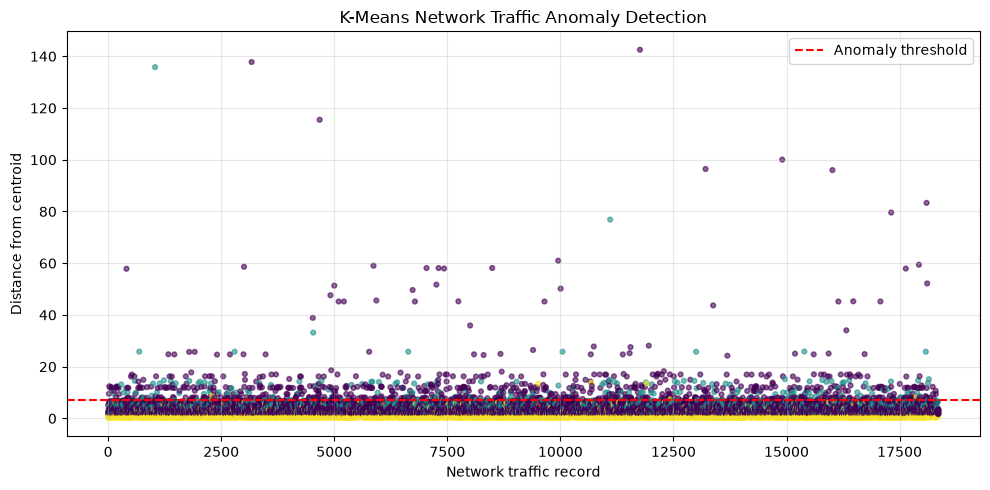

In [32]:
plt.figure(figsize=(10, 5))

plt.scatter(
    range(len(distances)),
    distances,
    c=new_df["cluster"],
    cmap="viridis",
    s=12,
    alpha=0.6
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly threshold"
)

plt.xlabel("Network traffic record")
plt.ylabel("Distance from centroid")
plt.title("K-Means Network Traffic Anomaly Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend()
plt.show()